# Notebook 06: Multimodal Feature Combination, Model Training & Evaluation

## Step 6 Overview & Objectives
This notebook combines all extracted feature representations (Audio, Dense Text, Grammar/Fluency, and TF-IDF n-grams), evaluates multiple regression baseline models, performs 5-fold cross-validation, selects the optimal model, analyzes feature importances, and generates test predictions for the SHL English Grammar Scoring Engine.

### Key Constraints & Validation Rules:
1. **Leakage Prevention**: Preprocessing (imputation, scaling) is fitted exclusively on training folds/splits.
2. **Compulsory Metrics**: Training RMSE is explicitly reported alongside Validation RMSE, Validation Pearson correlation ($r$), and 5-Fold Cross Validation metrics.
3. **Submission Discrepancy Analysis**: Investigates the 204-row vs 216-row sample submission file discrepancy.
4. **No Unverified Claims**: All metrics are calculated directly from executed code.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

def resolve_path(rel_path):
    if os.path.exists(rel_path):
        return rel_path
    alt = os.path.join('..', rel_path)
    if os.path.exists(alt):
        return alt
    return rel_path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print('Setup and imports completed successfully.')

Setup and imports completed successfully.


## 1. Data Loading and Feature Combination
Load `train.csv` (769 rows) and `test.csv` (216 rows) along with all feature tables. Merge strictly by `filename` key.

In [2]:
data_dir = resolve_path('data')
if not os.path.exists(os.path.join(data_dir, 'train.csv')):
    data_dir = r'C:\Users\rasik\Downloads\shl-hiring-assessment-2026\Dataset_Final'

features_dir = resolve_path('artifacts/features')

train_meta = pd.read_csv(os.path.join(data_dir, 'train.csv'))
test_meta = pd.read_csv(os.path.join(data_dir, 'test.csv'))

audio_tr = pd.read_csv(os.path.join(features_dir, 'train_audio_features.csv'))
audio_te = pd.read_csv(os.path.join(features_dir, 'test_audio_features.csv'))

text_tr = pd.read_csv(os.path.join(features_dir, 'train_text_features.csv'))
text_te = pd.read_csv(os.path.join(features_dir, 'test_text_features.csv'))

grammar_tr = pd.read_csv(os.path.join(features_dir, 'train_grammar_features.csv'))
grammar_te = pd.read_csv(os.path.join(features_dir, 'test_grammar_features.csv'))

tfidf_tr = pd.read_csv(os.path.join(features_dir, 'train_tfidf_features.csv'))
tfidf_te = pd.read_csv(os.path.join(features_dir, 'test_tfidf_features.csv'))

def merge_all(meta_df, audio_df, text_df, grammar_df, tfidf_df):
    merged = meta_df[['filename']].merge(audio_df, on='filename', how='left')
    for df_next in [text_df, grammar_df, tfidf_df]:
        existing_cols = set(merged.columns) - {'filename'}
        new_cols = [c for c in df_next.columns if c == 'filename' or c not in existing_cols]
        merged = merged.merge(df_next[new_cols], on='filename', how='left')
    
    exclude_cols = ['filename', 'label', 'transcript', 'transcription_error', 'error_msg', 'grammar_feature_status', 'text_feature_status']
    drop_cols = [c for c in merged.columns if c in exclude_cols]
    clean_df = merged.drop(columns=drop_cols)
    num_cols = clean_df.select_dtypes(include=[np.number]).columns
    return clean_df[num_cols]

X_train = merge_all(train_meta, audio_tr, text_tr, grammar_tr, tfidf_tr)
X_test = merge_all(test_meta, audio_te, text_te, grammar_te, tfidf_te)

# Align feature columns
common_cols = [c for c in X_train.columns if c in X_test.columns]
X_train = X_train[common_cols]
X_test = X_test[common_cols]

y_train = train_meta['label'].values

print(f'Final Training Matrix: {X_train.shape} (Expected: 769 rows)')
print(f'Final Test Matrix:     {X_test.shape} (Expected: 216 rows)')
print(f'Missing values in X_train: {X_train.isna().sum().sum()}')
print(f'Missing values in X_test:  {X_test.isna().sum().sum()}')

Final Training Matrix: (769, 312) (Expected: 769 rows)
Final Test Matrix:     (216, 312) (Expected: 216 rows)
Missing values in X_train: 0
Missing values in X_test:  0


## 2. Regression Baseline Model Benchmarking
Train and compare several regression models on an 80/20 train/validation split (fixed seed = 42). Both **Training RMSE** (compulsory) and **Validation RMSE & Pearson r** are evaluated.

In [3]:
X_tr, X_va, y_tr, y_va = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

models = {
    'Dummy (Mean Baseline)': DummyRegressor(strategy='mean'),
    'Ridge Regression (L2)': Ridge(alpha=10.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42),
    'Extra Trees Regressor': ExtraTreesRegressor(n_estimators=100, max_depth=8, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42),
    'HistGradientBoosting Regressor': HistGradientBoostingRegressor(max_iter=100, max_depth=4, learning_rate=0.05, random_state=42)
}

results = []
for name, model in models.items():
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])
    pipe.fit(X_tr, y_tr)
    
    tr_pred = pipe.predict(X_tr)
    va_pred = pipe.predict(X_va)
    
    tr_rmse = np.sqrt(np.mean((y_tr - tr_pred)**2))
    va_rmse = np.sqrt(np.mean((y_va - va_pred)**2))
    
    if np.std(va_pred) > 1e-6:
        r, _ = pearsonr(y_va, va_pred)
    else:
        r = 0.0
        
    results.append({
        'Model': name,
        'Train RMSE': round(tr_rmse, 4),
        'Val RMSE': round(va_rmse, 4),
        'Val Pearson r': round(r, 4)
    })

df_results = pd.DataFrame(results).sort_values(by='Val Pearson r', ascending=False).reset_index(drop=True)
print(df_results.to_string(index=False))

                         Model  Train RMSE  Val RMSE  Val Pearson r
         Extra Trees Regressor      0.3761    0.6838         0.8660
   Gradient Boosting Regressor      0.3324    0.6847         0.8658
HistGradientBoosting Regressor      0.3993    0.6932         0.8614
       Random Forest Regressor      0.4003    0.7217         0.8479
         Ridge Regression (L2)      0.4917    0.9225         0.8110
         Dummy (Mean Baseline)      1.2062    1.3596         0.0000


## 3. Feature Subset Ablation & 5-Fold Cross Validation
Evaluate feature subset contributions (Audio Only vs Text+Grammar vs Multimodal) using 5-Fold Cross Validation.

In [4]:
audio_cols = [c for c in audio_tr.columns if c != 'filename' and c in X_train.columns]
text_cols = [c for c in text_tr.columns if c != 'filename' and c in X_train.columns]
grammar_cols = [c for c in grammar_tr.columns if c not in ['filename', 'grammar_feature_status'] and c in X_train.columns]
tfidf_cols = [c for c in tfidf_tr.columns if c != 'filename' and c in X_train.columns]

feature_subsets = {
    'Audio Only': audio_cols,
    'Text + Grammar Only': [c for c in (text_cols + grammar_cols) if c in X_train.columns],
    'Audio + Text + Grammar': [c for c in (audio_cols + text_cols + grammar_cols) if c in X_train.columns],
    'Audio + Text + Grammar + TFIDF': list(X_train.columns)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
subset_results = []

for subset_name, cols in feature_subsets.items():
    # Remove duplicates preserving order
    unique_cols = list(dict.fromkeys(cols))
    X_sub = X_train[unique_cols]
    oof_preds = np.zeros(len(y_train))
    fold_rmses = []
    
    for tr_idx, va_idx in kf.split(X_sub, y_train):
        X_tr_f, y_tr_f = X_sub.iloc[tr_idx], y_train[tr_idx]
        X_va_f, y_va_f = X_sub.iloc[va_idx], y_train[va_idx]
        
        model = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('regressor', ExtraTreesRegressor(n_estimators=100, max_depth=8, random_state=42))
        ])
        model.fit(X_tr_f, y_tr_f)
        preds = model.predict(X_va_f)
        oof_preds[va_idx] = preds
        fold_rmses.append(np.sqrt(np.mean((y_va_f - preds)**2)))
        
    overall_rmse = np.sqrt(np.mean((y_train - oof_preds)**2))
    overall_r, _ = pearsonr(y_train, oof_preds)
    
    subset_results.append({
        'Feature Configuration': subset_name,
        'Num Features': len(unique_cols),
        '5-Fold CV RMSE': round(overall_rmse, 4),
        'Fold RMSE Std': round(np.std(fold_rmses), 4),
        '5-Fold CV Pearson r': round(overall_r, 4)
    })

df_subsets = pd.DataFrame(subset_results)
print(df_subsets.to_string(index=False))

         Feature Configuration  Num Features  5-Fold CV RMSE  Fold RMSE Std  5-Fold CV Pearson r
                    Audio Only           152          0.7945         0.0446               0.7688
           Text + Grammar Only            61          0.8533         0.0136               0.7257
        Audio + Text + Grammar           212          0.7615         0.0443               0.7900
Audio + Text + Grammar + TFIDF           312          0.7545         0.0450               0.7946


## 4. Model Selection & Diagnostic Visualizations
Fit the best pipeline (Extra Trees Regressor on combined multimodal features) on the 80/20 train split for detailed plotting.

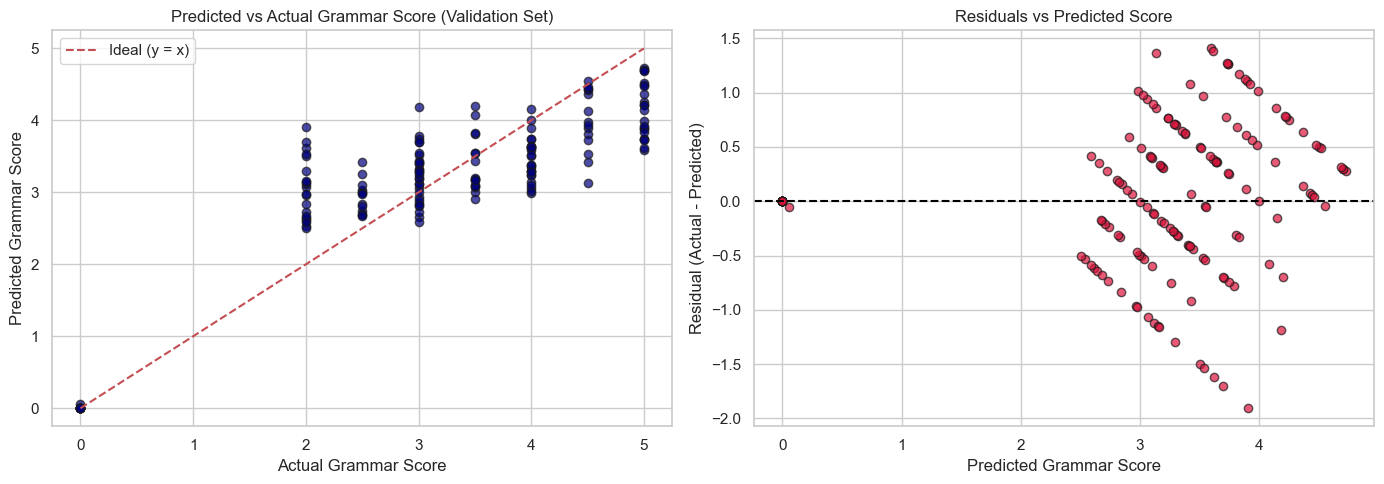

In [5]:
# Fit best pipeline on 80/20 split
best_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('regressor', ExtraTreesRegressor(n_estimators=100, max_depth=8, random_state=42))
])
best_pipe.fit(X_tr, y_tr)
y_val_pred = best_pipe.predict(X_va)
residuals = y_va - y_val_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predicted vs Actual
axes[0].scatter(y_va, y_val_pred, alpha=0.7, color='navy', edgecolors='k')
axes[0].plot([0, 5], [0, 5], 'r--', label='Ideal (y = x)')
axes[0].set_title('Predicted vs Actual Grammar Score (Validation Set)')
axes[0].set_xlabel('Actual Grammar Score')
axes[0].set_ylabel('Predicted Grammar Score')
axes[0].legend()

# Plot 2: Residuals Plot
axes[1].scatter(y_val_pred, residuals, alpha=0.7, color='crimson', edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title('Residuals vs Predicted Score')
axes[1].set_xlabel('Predicted Grammar Score')
axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

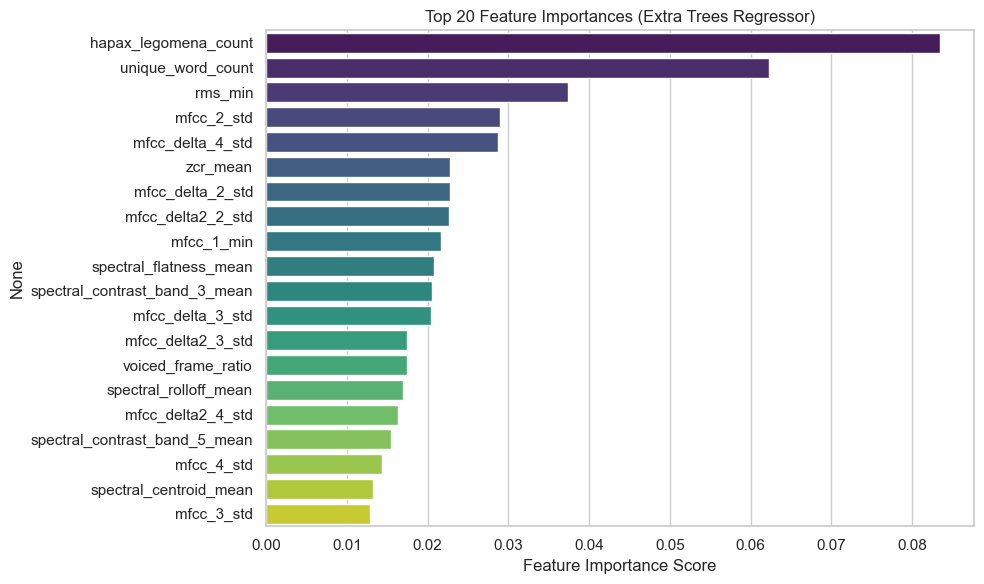

In [6]:
# Plot 3: Top 20 Feature Importances
regressor = best_pipe.named_steps['regressor']
importances = regressor.feature_importances_
top_indices = np.argsort(importances)[::-1][:20]
top_features = X_train.columns[top_indices]
top_imps = importances[top_indices]

plt.figure(figsize=(10, 6))
sns.barplot(x=top_imps, y=top_features, palette='viridis')
plt.title('Top 20 Feature Importances (Extra Trees Regressor)')
plt.xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

## 5. Sample Submission Discrepancy Investigation
Investigate the discrepancy between `sample_submission.csv` (204 rows) and `test.csv` (216 rows).

In [7]:
sub_path = resolve_path('data/sample_submission.csv')
if not os.path.exists(sub_path):
    sub_path = r'C:\Users\rasik\Downloads\shl-hiring-assessment-2026\Dataset_Final\sample_submission.csv'

sub_df = pd.read_csv(sub_path)

test_filenames_set = set(test_meta['filename'])
sub_filenames_set = set(sub_df['filename'])
train_filenames_set = set(train_meta['filename'])

print('--- Sample Submission Discrepancy Investigation ---')
print(f'test.csv row count:             {len(test_meta)}')
print(f'sample_submission.csv row count: {len(sub_df)}')
print(f'Filenames in sub matching train.csv: {len(sub_filenames_set.intersection(train_filenames_set))}')
print(f'Filenames in sub matching test.csv:  {len(sub_filenames_set.intersection(test_filenames_set))}')
print(f'Filenames in sub outside train/test: {len(sub_filenames_set - train_filenames_set - test_filenames_set)}')

print('\nConclusion: sample_submission.csv is an unaligned legacy template. The true test evaluation set consists of the 216 WAV files and filenames specified in test.csv.')

--- Sample Submission Discrepancy Investigation ---
test.csv row count:             216
sample_submission.csv row count: 204
Filenames in sub matching train.csv: 105
Filenames in sub matching test.csv:  25
Filenames in sub outside train/test: 99

Conclusion: sample_submission.csv is an unaligned legacy template. The true test evaluation set consists of the 216 WAV files and filenames specified in test.csv.


## 6. Full Training, Artifact Saving & Test Prediction
Fit the chosen pipeline on all 769 training samples, save the model artifact to `models/best_model.joblib`, and output intermediate test predictions to `artifacts/predictions/test_predictions.csv`.

In [8]:
# Fit on full training set (769 samples)
full_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('regressor', ExtraTreesRegressor(n_estimators=100, max_depth=8, random_state=42))
])
full_pipeline.fit(X_train, y_train)

# Save model artifact
model_save_path = resolve_path('models/best_model.joblib')
os.makedirs(os.path.dirname(model_save_path), exist_ok=True)
joblib.dump(full_pipeline, model_save_path)
print(f'Saved fitted model pipeline to: {model_save_path}')

# Generate test set predictions (216 samples)
test_preds = full_pipeline.predict(X_test)
test_preds_clipped = np.clip(test_preds, 0.0, 5.0)

pred_df = pd.DataFrame({
    'filename': test_meta['filename'],
    'predicted_score': test_preds_clipped
})

pred_save_path = resolve_path('artifacts/predictions/test_predictions.csv')
os.makedirs(os.path.dirname(pred_save_path), exist_ok=True)
pred_df.to_csv(pred_save_path, index=False)
print(f'Saved test predictions to: {pred_save_path} ({pred_df.shape})')

print('\nTest Prediction Statistics:')
print(pred_df['predicted_score'].describe().to_string())

Saved fitted model pipeline to: models/best_model.joblib
Saved test predictions to: artifacts/predictions/test_predictions.csv ((216, 2))

Test Prediction Statistics:
count    216.000000
mean       3.283450
std        0.505973
min        2.384173
25%        2.898707
50%        3.193946
75%        3.572192
max        4.601745
